# NumPy & PyTorch tutorial

This tutorial introduces NumPy and PyTorch, two core libraries for numerical computing and deep learning.

In [2]:
import numpy as np
import torch

## Working with multidimensional data

In deep learning, data and model parameters are represented by multidimensional collections of numbers. NumPy calls these objects **arrays**, while PyTorch calls them **tensors**. Both store values of a single data type in a structured way and provide efficient operations for manipulating all those values at once.

A tensor generalizes familiar mathematical objects to any number of dimensions:

- A **0D tensor** is a scalar: a single number.
- A **1D tensor** is a vector: a sequence of numbers.
- A **2D tensor** is a matrix: values arranged in rows and columns.
- An **nD tensor** extends this idea to more dimensions.

The meaning of each dimension depends on the data. A 2D tensor could represent a grayscale image with dimensions `(height, width)`. A color image is often represented by a 3D tensor with dimensions `(channels, height, width)`. A batch of color images adds another dimension and commonly has shape `(batch, channels, height, width)`. Keeping track of the meaning and order of dimensions is an important part of working with deep-learning models.

NumPy arrays and PyTorch tensors deliberately have similar interfaces. NumPy is a general-purpose numerical computing library whose arrays normally live in CPU memory. PyTorch builds on the same array-programming concepts and adds features needed for deep learning, including accelerator support and automatic differentiation. A NumPy array and a CPU tensor can even share their underlying memory, as we will see later.

In this tutorial, each NumPy example is followed by an equivalent PyTorch example.

For more information, consult the [NumPy documentation](https://numpy.org/doc/stable/) and the [PyTorch documentation](https://pytorch.org/docs/stable/index.html).

This tutorial is inspired by the PyTorch [Learn the Basics](https://pytorch.org/tutorials/beginner/basics/intro.html) series.

### 1. Python lists and numerical arrays

A Python list is a general-purpose container. A NumPy array stores values of one data type and supports numerical operations on all its elements at once. Notice that multiplying a list repeats it, while multiplying a NumPy array multiplies each value.

**NumPy example**

In [3]:
python_values = [1, 2, 3]
numpy_values = np.array([1, 2, 3])

print("Python list multiplied by 2:", python_values * 2)
print("NumPy array multiplied by 2:", numpy_values * 2)

Python list multiplied by 2: [1, 2, 3, 1, 2, 3]
NumPy array multiplied by 2: [2 4 6]


**PyTorch example**

A PyTorch tensor behaves like the NumPy array in this example.

In [4]:
torch_values = torch.tensor([1, 2, 3])
print("PyTorch tensor multiplied by 2:", torch_values * 2)

PyTorch tensor multiplied by 2: tensor([2, 4, 6])


### 2. Initializing NumPy arrays and PyTorch tensors

Arrays and tensors can be created directly from Python data, filled with constant or random values, or created using the properties of an existing array or tensor. When no data type is specified, NumPy and PyTorch infer one from the input values.

**NumPy example: create an array from Python data**

In [5]:
list_of_lists = [[1, 2], [3, 4]]
numpy_from_data = np.array(list_of_lists)

print(numpy_from_data)
print("shape:", numpy_from_data.shape)
print("data type:", numpy_from_data.dtype)

[[1 2]
 [3 4]]
shape: (2, 2)
data type: int64


**PyTorch example: create a tensor from Python data**

In [6]:
torch_from_data = torch.tensor(list_of_lists)

print(torch_from_data)
print("shape:", torch_from_data.shape)
print("data type:", torch_from_data.dtype)

tensor([[1, 2],
        [3, 4]])
shape: torch.Size([2, 2])
data type: torch.int64


A `shape` is a tuple containing the size of every dimension. Both libraries can use a shape to create arrays or tensors filled with zeros, ones, or random values. Explicitly setting the data type avoids relying on different defaults.

**NumPy example: create arrays from a shape**

In [7]:
shape = (3, 4)
rng = np.random.default_rng(seed=42)
numpy_random = rng.random(shape, dtype=np.float32)
numpy_zeros = np.zeros(shape, dtype=np.float32)
numpy_ones = np.ones(shape, dtype=np.float32)

print("Random array:\n", numpy_random)
print("Zeros array:\n", numpy_zeros)
print("Ones array:\n", numpy_ones)

Random array:
 [[0.08925092 0.773956   0.6545715  0.43887842]
 [0.43301523 0.8585979  0.08594561 0.697368  ]
 [0.20146948 0.09417731 0.52647895 0.9756223 ]]
Zeros array:
 [[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
Ones array:
 [[1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]]


**PyTorch example: create tensors from a shape**

In [8]:
generator = torch.Generator().manual_seed(42)
torch_random = torch.rand(shape, dtype=torch.float32, generator=generator)
torch_zeros = torch.zeros(shape, dtype=torch.float32)
torch_ones = torch.ones(shape, dtype=torch.float32)

print("Random tensor:\n", torch_random)
print("Zeros tensor:\n", torch_zeros)
print("Ones tensor:\n", torch_ones)

Random tensor:
 tensor([[0.8823, 0.9150, 0.3829, 0.9593],
        [0.3904, 0.6009, 0.2566, 0.7936],
        [0.9408, 0.1332, 0.9346, 0.5936]])
Zeros tensor:
 tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])
Ones tensor:
 tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]])


The `*_like` functions copy the shape and, by default, the data type of an existing array or tensor. PyTorch also lets us override properties such as the data type.

**NumPy example: initialize from an existing array**

In [9]:
numpy_base = np.array([[1, 2, 3], [4, 5, 6]], dtype=np.int16)
numpy_ones_like = np.ones_like(numpy_base)
numpy_float_like = np.zeros_like(numpy_base, dtype=np.float64)

print("Base:\n", numpy_base, numpy_base.dtype)
print("Ones with matching properties:\n", numpy_ones_like, numpy_ones_like.dtype)
print("Zeros with an overridden data type:\n", numpy_float_like, numpy_float_like.dtype)

Base:
 [[1 2 3]
 [4 5 6]] int16
Ones with matching properties:
 [[1 1 1]
 [1 1 1]] int16
Zeros with an overridden data type:
 [[0. 0. 0.]
 [0. 0. 0.]] float64


**PyTorch example: initialize from an existing tensor**

In [10]:
torch_base = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.int16)
torch_ones_like = torch.ones_like(torch_base)
torch_random_like = torch.rand_like(torch_base, dtype=torch.float64)

print("Base:\n", torch_base, torch_base.dtype)
print("Ones with matching properties:\n", torch_ones_like, torch_ones_like.dtype)
print("Random values with an overridden data type:\n", torch_random_like, torch_random_like.dtype)

Base:
 tensor([[1, 2, 3],
        [4, 5, 6]], dtype=torch.int16) torch.int16
Ones with matching properties:
 tensor([[1, 1, 1],
        [1, 1, 1]], dtype=torch.int16) torch.int16
Random values with an overridden data type:
 tensor([[0.3706, 0.0920, 0.4941],
        [0.0637, 0.7484, 0.6863]], dtype=torch.float64) torch.float64


### 3. Visualizing arrays and tensors

An array's or tensor's shape describes how its values are organized, but the meaning of those values depends on the problem. The same numerical structure might represent a geometric vector, class probabilities, an image, or something entirely different. Plotting the data can make that meaning easier to understand.

Matplotlib works naturally with NumPy arrays. It can also plot CPU tensors that are not tracking gradients; converting such a tensor with `.numpy()` makes that hand-off explicit.

In [11]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


#### One-dimensional data

A one-dimensional array with three values can be interpreted as a vector in three-dimensional space.

**NumPy example: plot an array as a vector**

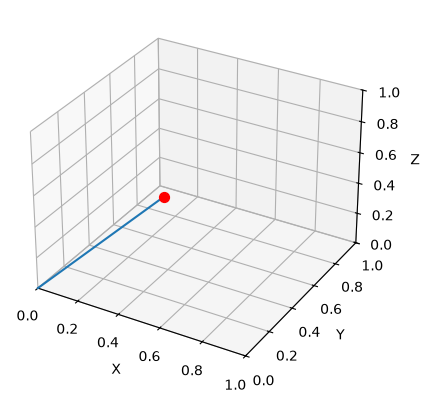

In [12]:
numpy_vector = np.array([0.08, 0.9, 0.02], dtype=np.float32)

figure = plt.figure()
axis = figure.add_subplot(111, projection="3d")
axis.scatter(*numpy_vector, color="red", s=50)
axis.plot([0, numpy_vector[0]], [0, numpy_vector[1]], [0, numpy_vector[2]])
axis.set(xlabel="X", ylabel="Y", zlabel="Z", xlim=(0, 1), ylim=(0, 1), zlim=(0, 1))
plt.show()

The same three values could instead represent scores or probabilities for three classes.

**PyTorch example: plot a tensor as class probabilities**

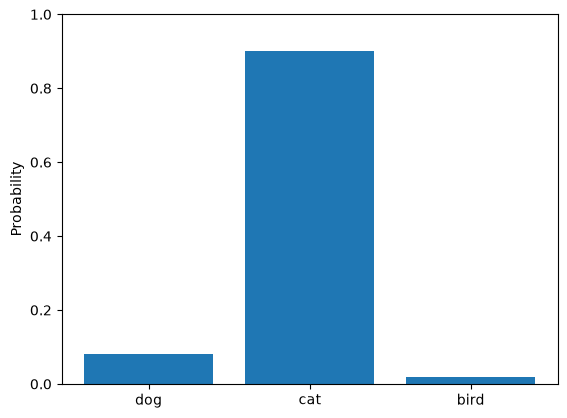

In [13]:
torch_probabilities = torch.tensor([0.08, 0.9, 0.02], dtype=torch.float32)

plt.bar(["dog", "cat", "bird"], torch_probabilities.numpy())
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.show()

#### Images and batches

A color image uses three channels: red, green, and blue. NumPy and Matplotlib commonly represent an image as `(height, width, channels)`. PyTorch models commonly use `(channels, height, width)` and add a leading batch dimension during training: `(batch, channels, height, width)`.

The examples below describe the same 2-by-4-pixel image using each convention.

**NumPy example: plot an image in `(height, width, channels)` format**

NumPy image shape: (2, 4, 3)


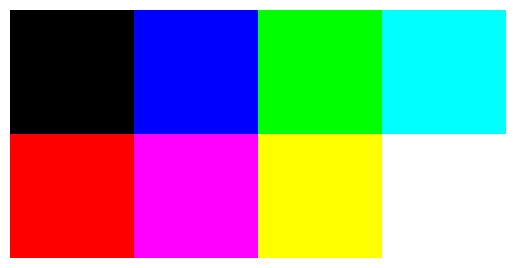

In [14]:
red_channel = [[0, 0, 0, 0],
               [1, 1, 1, 1]]
green_channel = [[0, 0, 1, 1],
                 [0, 0, 1, 1]]
blue_channel = [[0, 1, 0, 1],
                [0, 1, 0, 1]]

numpy_image = np.stack([red_channel, green_channel, blue_channel], axis=-1).astype(np.float32)
print("NumPy image shape:", numpy_image.shape)

plt.imshow(numpy_image, interpolation="none")
plt.axis("off")
plt.show()

**PyTorch example: plot an image from `(batch, channels, height, width)` format**

We remove the batch dimension by selecting its first item and use `permute` to move the channel dimension to the end for Matplotlib.

PyTorch image batch shape: torch.Size([1, 3, 2, 4])
Shape passed to Matplotlib: torch.Size([2, 4, 3])


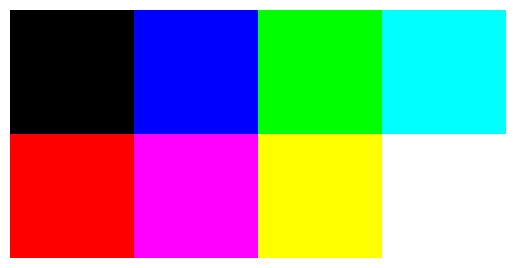

In [15]:
torch_image = torch.tensor([red_channel, green_channel, blue_channel], dtype=torch.float32)
torch_image_batch = torch_image.unsqueeze(0)
display_image = torch_image_batch[0].permute(1, 2, 0)

print("PyTorch image batch shape:", torch_image_batch.shape)
print("Shape passed to Matplotlib:", display_image.shape)

plt.imshow(display_image.numpy(), interpolation="none")
plt.axis("off")
plt.show()

### 4. Shape, number of dimensions, and data type

Three properties help us understand an array or tensor:

- `shape` gives the size of every dimension.
- `ndim` gives the number of dimensions.
- `dtype` gives the type used to store each value.

Deep-learning models commonly use 32-bit floating-point values.

**NumPy example**

In [16]:
numpy_matrix = np.array([[1, 2, 3], [4, 5, 6]], dtype=np.float32)

print(numpy_matrix)
print("shape:", numpy_matrix.shape)
print("number of dimensions:", numpy_matrix.ndim)
print("data type:", numpy_matrix.dtype)

[[1. 2. 3.]
 [4. 5. 6.]]
shape: (2, 3)
number of dimensions: 2
data type: float32


**PyTorch example**

In [17]:
torch_matrix = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float32)

print(torch_matrix)
print("shape:", torch_matrix.shape)
print("number of dimensions:", torch_matrix.ndim)
print("data type:", torch_matrix.dtype)

tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape: torch.Size([2, 3])
number of dimensions: 2
data type: torch.float32


### 5. Indexing and slicing

Indexing selects individual values, while slicing selects a range of values. Indices start at zero. For a two-dimensional array, the first index selects a row and the second selects a column. A colon (`:`) means “select everything along this dimension.”

**NumPy example**

In [18]:
numpy_grid = np.array([[10, 11, 12],
                       [20, 21, 22],
                       [30, 31, 32]])

print("Value at row 1, column 2:", numpy_grid[1, 2])
print("First row:", numpy_grid[0, :])
print("Second column:", numpy_grid[:, 1])
print("First two rows and columns:\n", numpy_grid[:2, :2])

Value at row 1, column 2: 22
First row: [10 11 12]
Second column: [11 21 31]
First two rows and columns:
 [[10 11]
 [20 21]]


**PyTorch example**

In [19]:
torch_grid = torch.tensor([[10, 11, 12],
                           [20, 21, 22],
                           [30, 31, 32]])

print("Value at row 1, column 2:", torch_grid[1, 2])
print("First row:", torch_grid[0, :])
print("Second column:", torch_grid[:, 1])
print("First two rows and columns:\n", torch_grid[:2, :2])

Value at row 1, column 2: tensor(22)
First row: tensor([10, 11, 12])
Second column: tensor([11, 21, 31])
First two rows and columns:
 tensor([[10, 11],
        [20, 21]])


### 6. Element-wise operations and matrix multiplication

NumPy and PyTorch provide familiar arithmetic operators as well as mathematical functions such as sine, cosine, and square root. Addition, subtraction, multiplication, and division operate **element by element** when their inputs have the same shape. A scalar can also be applied to every element.

Element-wise multiplication with `*` is different from matrix multiplication with `@`. For matrix multiplication, the inner dimensions must match: an array with shape `(m, n)` can be multiplied by one with shape `(n, p)`, producing shape `(m, p)`.

**NumPy example**

In [20]:
numpy_left = np.array([[1, 2], [3, 4]], dtype=np.float32)
numpy_right = np.array([[5, 6], [7, 8]], dtype=np.float32)

print("Sum:\n", numpy_left + numpy_right)
print("Difference:\n", numpy_left - numpy_right)
print("Element-wise multiplication:\n", numpy_left * numpy_right)
print("Element-wise division:\n", numpy_left / numpy_right)
print("Multiplication by a scalar:\n", numpy_left * 5)
print("Matrix multiplication:\n", numpy_left @ numpy_right)
print("Sine of every element:\n", np.sin(numpy_left))

Sum:
 [[ 6.  8.]
 [10. 12.]]
Difference:
 [[-4. -4.]
 [-4. -4.]]
Element-wise multiplication:
 [[ 5. 12.]
 [21. 32.]]
Element-wise division:
 [[0.2        0.33333334]
 [0.42857143 0.5       ]]
Multiplication by a scalar:
 [[ 5. 10.]
 [15. 20.]]
Matrix multiplication:
 [[19. 22.]
 [43. 50.]]
Sine of every element:
 [[ 0.841471   0.9092974]
 [ 0.14112   -0.7568025]]


**PyTorch example**

In [21]:
torch_left = torch.tensor([[1, 2], [3, 4]], dtype=torch.float32)
torch_right = torch.tensor([[5, 6], [7, 8]], dtype=torch.float32)

print("Sum:\n", torch_left + torch_right)
print("Difference:\n", torch_left - torch_right)
print("Element-wise multiplication:\n", torch_left * torch_right)
print("Element-wise division:\n", torch_left / torch_right)
print("Multiplication by a scalar:\n", torch_left * 5)
print("Matrix multiplication:\n", torch_left @ torch_right)
print("Sine of every element:\n", torch.sin(torch_left))

Sum:
 tensor([[ 6.,  8.],
        [10., 12.]])
Difference:
 tensor([[-4., -4.],
        [-4., -4.]])
Element-wise multiplication:
 tensor([[ 5., 12.],
        [21., 32.]])
Element-wise division:
 tensor([[0.2000, 0.3333],
        [0.4286, 0.5000]])
Multiplication by a scalar:
 tensor([[ 5., 10.],
        [15., 20.]])
Matrix multiplication:
 tensor([[19., 22.],
        [43., 50.]])
Sine of every element:
 tensor([[ 0.8415,  0.9093],
        [ 0.1411, -0.7568]])


### 7. Reshaping and aggregating along a dimension

Reshaping changes how the same values are arranged. Aggregations such as `sum` and `mean` can reduce all values to one result or reduce values along a selected dimension. NumPy calls this an `axis`; PyTorch calls it a `dim`.

**NumPy example**

In [22]:
numpy_values = np.arange(1, 7, dtype=np.float32)
numpy_table = numpy_values.reshape(2, 3)

print("Reshaped array:\n", numpy_table)
print("Sum of each column:", numpy_table.sum(axis=0))
print("Mean of each row:", numpy_table.mean(axis=1))

Reshaped array:
 [[1. 2. 3.]
 [4. 5. 6.]]
Sum of each column: [5. 7. 9.]
Mean of each row: [2. 5.]


**PyTorch example**

In [23]:
torch_values = torch.arange(1, 7, dtype=torch.float32)
torch_table = torch_values.reshape(2, 3)

print("Reshaped tensor:\n", torch_table)
print("Sum of each column:", torch_table.sum(dim=0))
print("Mean of each row:", torch_table.mean(dim=1))

Reshaped tensor:
 tensor([[1., 2., 3.],
        [4., 5., 6.]])
Sum of each column: tensor([5., 7., 9.])
Mean of each row: tensor([2., 5.])


### 8. Broadcasting

Broadcasting allows arrays or tensors with different but compatible shapes to participate in the same element-wise operation. Smaller inputs are virtually expanded without physically copying their data.

To determine whether two shapes are broadcastable:

1. Align their dimensions on the right.
2. Compare the dimensions from right to left.
3. Each pair must be equal, one of them must be `1`, or one of the dimensions must be absent.

The result uses the non-`1` size of each aligned pair. For example, a `(3, 1)` column and a `(1, 4)` row produce a `(3, 4)` result. The broadcasting rules are shared by [NumPy](https://numpy.org/doc/stable/user/basics.broadcasting.html) and [PyTorch](https://pytorch.org/docs/stable/notes/broadcasting.html).

**NumPy example**

In [24]:
numpy_base_values = np.array([[10], [20], [30]])  # shape: (3, 1)
numpy_adjustments = np.array([[0, 1, 2, 3]])      # shape: (1, 4)
numpy_result = numpy_base_values + numpy_adjustments

print("(3, 1) + (1, 4) gives:", numpy_result.shape)
print(numpy_result)

numpy_x = np.empty((5, 3, 4, 1))
numpy_y = np.empty((3, 1, 1))
print("(5, 3, 4, 1) + (3, 1, 1) gives:", (numpy_x + numpy_y).shape)

numpy_incompatible = np.empty((5, 2, 4, 1))
try:
    numpy_incompatible + numpy_y
except ValueError as error:
    print("Incompatible shapes produce an error:", error)

(3, 1) + (1, 4) gives: (3, 4)
[[10 11 12 13]
 [20 21 22 23]
 [30 31 32 33]]
(5, 3, 4, 1) + (3, 1, 1) gives: (5, 3, 4, 1)
Incompatible shapes produce an error: operands could not be broadcast together with shapes (5,2,4,1) (3,1,1) 


**PyTorch example**

In [25]:
torch_base_values = torch.tensor([[10], [20], [30]])  # shape: (3, 1)
torch_adjustments = torch.tensor([[0, 1, 2, 3]])      # shape: (1, 4)
torch_result = torch_base_values + torch_adjustments

print("(3, 1) + (1, 4) gives:", torch_result.shape)
print(torch_result)

torch_x = torch.empty((5, 3, 4, 1))
torch_y = torch.empty((3, 1, 1))
print("(5, 3, 4, 1) + (3, 1, 1) gives:", (torch_x + torch_y).shape)

torch_incompatible = torch.empty((5, 2, 4, 1))
try:
    torch_incompatible + torch_y
except RuntimeError as error:
    print("Incompatible shapes produce an error:", error)

(3, 1) + (1, 4) gives: torch.Size([3, 4])
tensor([[10, 11, 12, 13],
        [20, 21, 22, 23],
        [30, 31, 32, 33]])
(5, 3, 4, 1) + (3, 1, 1) gives: torch.Size([5, 3, 4, 1])
Incompatible shapes produce an error: The size of tensor a (2) must match the size of tensor b (3) at non-singleton dimension 1


### 9. Converting between NumPy arrays and PyTorch tensors

`torch.from_numpy` creates a CPU tensor that shares its underlying memory with the NumPy array. Changing one may therefore change the other. The NumPy data type is preserved during conversion.

Use `torch.tensor(numpy_array)` instead when you need an independent copy. In the other direction, calling `.numpy()` on a CPU tensor also returns an array that shares memory with that tensor.

**Example**

In [26]:
numpy_source = np.array([1.0, 2.0, 3.0], dtype=np.float32)
print(numpy_source)
print(numpy_source.dtype)

shared_tensor = torch.from_numpy(numpy_source)
copied_tensor = torch.tensor(numpy_source)

numpy_source[0] = 99.0

print("Changed NumPy array:", numpy_source)
print("Tensor sharing its memory:", shared_tensor)
print("Independent tensor copy:", copied_tensor)

numpy_view = copied_tensor.numpy()
copied_tensor[1] = -5.0
print("Changed tensor:", copied_tensor)
print("NumPy view sharing its memory:", numpy_view)

[1. 2. 3.]
float32
Changed NumPy array: [99.  2.  3.]
Tensor sharing its memory: tensor([99.,  2.,  3.])
Independent tensor copy: tensor([1., 2., 3.])
Changed tensor: tensor([ 1., -5.,  3.])
NumPy view sharing its memory: [ 1. -5.  3.]


### 10. Automatic differentiation

Training a neural network requires gradients that describe how a change in each model parameter would affect the loss. NumPy can perform the numerical operations, but it does not automatically build the computation graph needed to calculate these gradients. With NumPy, we must derive or implement them ourselves.

PyTorch's automatic differentiation system is called **autograd**. During the forward pass, it records the operations performed on tensors that require gradients. During the backward pass, it follows that graph in reverse and applies the chain rule.

**NumPy example: calculate a gradient manually**

For $f(x) = \sum x^2$, the derivative is $2x$.

In [27]:
numpy_x = np.array([1.0, 2.0, 3.0], dtype=np.float32)
numpy_loss = (numpy_x ** 2).sum()
numpy_gradient = 2 * numpy_x

print("Loss:", numpy_loss)
print("Manually calculated gradient:", numpy_gradient)

Loss: 14.0
Manually calculated gradient: [2. 4. 6.]


**PyTorch example: calculate the gradient automatically**

Tensors do not track gradients by default. Setting `requires_grad=True` on a floating-point tensor asks PyTorch to record operations involving it. Calling `backward()` on the resulting scalar loss computes the gradient and stores it in `torch_x.grad`.

In [28]:
torch_x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
print("Requires gradients:", torch_x.requires_grad)
print("Gradient before backward:", torch_x.grad)

torch_loss = (torch_x ** 2).sum()
print("Function that created the loss:", torch_loss.grad_fn)
torch_loss.backward()

print("Loss:", torch_loss.item())
print("Automatically calculated gradient:", torch_x.grad)

Requires gradients: True
Gradient before backward: None
Function that created the loss: <SumBackward0 object at 0x000001FADE7D1960>
Loss: 14.0
Automatically calculated gradient: tensor([2., 4., 6.])


#### Following a larger computation graph

Consider the element-wise calculation $y = x^2w + 1$. Its derivative with respect to $x$ is $2xw$. The intermediate tensors expose a `grad_fn` that points into the computation graph.

Neural-network losses are normally scalars. Here, `output` is a matrix, so we sum it to create one scalar loss before calling `backward()`.

In [29]:
tensor1 = torch.tensor([[1.0, 2.0], [3.0, 4.0]], requires_grad=True)
tensor2 = torch.tensor([[4.0, 3.0], [2.0, 1.0]])

intermediate_output = tensor1.pow(2) * tensor2
output = intermediate_output + 1
loss = output.sum()

print("Intermediate grad function:", intermediate_output.grad_fn)
print("Output grad function:", output.grad_fn)
print("Scalar loss:", loss.item())

loss.backward()
expected_gradient = 2 * tensor1.detach() * tensor2
print("Gradient calculated by autograd:\n", tensor1.grad)
print("Expected gradient 2 * x * w:\n", expected_gradient)

Intermediate grad function: <MulBackward0 object at 0x000001FADE7D3E50>
Output grad function: <AddBackward0 object at 0x000001FADE7D1510>
Scalar loss: 54.0
Gradient calculated by autograd:
 tensor([[ 8., 12.],
        [12.,  8.]])
Expected gradient 2 * x * w:
 tensor([[ 8., 12.],
        [12.,  8.]])


#### Backpropagating from a non-scalar output

Calling `backward()` without an argument is only defined when the starting tensor is a scalar. Because `output` is a matrix, PyTorch needs an incoming gradient for every element. Passing `torch.ones_like(output)` supplies an incoming gradient of `1` everywhere. This is equivalent to summing all output elements first, because the derivative of that sum with respect to each element is `1`.

Building on the preceding example, we save the gradient produced by `loss.backward()`, clear it, and recompute the same forward pass. We must recompute because PyTorch releases the computation graph after `backward()` by default. We can then start the second backward pass directly from the matrix `output` and verify that its gradient is identical.

In [30]:
gradient_from_sum = tensor1.grad.clone()
tensor1.grad.zero_()

# Recompute the same forward pass to create a new computation graph.
intermediate_output = tensor1.pow(2) * tensor2
output = intermediate_output + 1
output.backward(gradient=torch.ones_like(output))
gradient_from_ones = tensor1.grad.clone()

print("Gradient after output.sum().backward():\n", gradient_from_sum)
print("Gradient after output.backward(ones):\n", gradient_from_ones)
print("Gradients are equal:", torch.equal(gradient_from_sum, gradient_from_ones))

Gradient after output.sum().backward():
 tensor([[ 8., 12.],
        [12.,  8.]])
Gradient after output.backward(ones):
 tensor([[ 8., 12.],
        [12.,  8.]])
Gradients are equal: True


#### Gradients accumulate

Every call to `backward()` adds newly calculated values to a tensor's existing `.grad`. This is useful in some advanced workflows, but training loops usually clear gradients before the next backward pass with `optimizer.zero_grad()` or by setting them to zero explicitly.

In [31]:
first_gradient = tensor1.grad.clone()
second_loss = (tensor1.pow(2) * tensor2 + 1).sum()
second_loss.backward()

print("Gradient after a second backward pass:\n", tensor1.grad)
print("Twice the first gradient:\n", 2 * first_gradient)

tensor1.grad.zero_()
print("Gradient after zeroing:\n", tensor1.grad)

Gradient after a second backward pass:
 tensor([[16., 24.],
        [24., 16.]])
Twice the first gradient:
 tensor([[16., 24.],
        [24., 16.]])
Gradient after zeroing:
 tensor([[0., 0.],
        [0., 0.]])


### 11. Using accelerators

NumPy arrays normally live in CPU memory. PyTorch tensors can also be placed on supported hardware accelerators, such as CUDA-enabled GPUs, which can perform many tensor operations in parallel.

A device describes where a tensor is stored and where its operations are performed. Tensors involved in the same operation must be on the same device. The example below selects a CUDA device when one is available. In case no CUDA-capable device is present on the machine, `device` falls back to the CPU.

**PyTorch example: select a device and move a tensor**

In [33]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cpu_tensor = torch.tensor([1.0, 2.0, 3.0])
device_tensor = cpu_tensor.to(device)

print("Selected device:", device)
print("Original tensor device:", cpu_tensor.device)
print("Moved tensor device:", device_tensor.device)

Selected device: cpu
Original tensor device: cpu
Moved tensor device: cpu
